# Capstone — Build, Train & Report a Deep Learning Model

This is **your** project. Across the course you built — by hand, on toy numbers in
the sandbox — tensors, the training loop, CNNs, RNNs/LSTMs, regularization, and the
habit of reading loss curves. Now you put it all together on a **real dataset you
choose**, and you are judged on a **held-out test set** you only touch once.

Unlike the weekly labs, this notebook is **mostly scaffold**. It gives you the
boring-but-essential spine — `device`/seed setup, `train()` / `evaluate()` /
`plot_curves()`, and a one-shot test-evaluation cell — so you can spend your effort
on the part that matters: the **model** and the **experiments**. Everything marked
**🔧 TODO** is yours to fill in. The notebook will not learn anything until you do.

> **Runtime → Change runtime type → T4 GPU** before you start. Then run the setup
> cell and confirm it prints `cuda`.

---

## Choose your track

Pick **one** track below and uncomment its data-loading stub in Beat 3. All three
use a *real* public dataset and target a model family you already met in the course.
You are free to invent your own task instead (any real dataset + a model you train)
— these three are just well-scoped starting points.

| Track | Dataset (real, auto-downloaded) | Model you build | Beat this baseline |
|---|---|---|---|
| **A · Vision** | **CIFAR-10** — 60k 32×32 colour photos, 10 classes | a **CNN** (Conv → ReLU → Pool …) | majority class = **10%**; aim **> 65%** test accuracy |
| **B · Text** | **Names-by-language** — ~20k surnames, 18 languages (PyTorch's char-RNN dataset) | a char-level **LSTM** classifier | majority class (English) ≈ **27%**; aim **> 70%** |
| **C · Tabular** | **Penguins** — 344 rows, 7 features, 3 species (seaborn) | an **MLP** | majority class ≈ **44%**; aim **> 95%** |

Each track is sized to train in **under ~5 minutes on a T4**. The spine below is
**track-agnostic**: write your dataset loader and model so that `train_loader`,
`val_loader`, `test_loader`, and `model` exist, and the generic `train()` /
`evaluate()` helpers just work.

> **The one rule that defines this capstone:** *tune on validation, report on test.*
> Choose your model, learning rate, epochs, and regularization using the **validation**
> set. Touch the **test** set exactly **once**, at the very end, for the number you
> report. Peeking at test while tuning turns it into a second validation set and
> quietly inflates your result — the rubric checks for this.

## 1 · Setup, GPU check & the spine

Run this once. It imports everything, fixes the seed so your runs are reproducible
(the rubric expects a fixed seed), picks the GPU, and defines the **spine** you'll
reuse no matter which track you chose:

- `accuracy(logits, y)` — exact-match accuracy for a batch of logits.
- `train(...)` — the generic five-step training loop with a validation pass each
  epoch; returns the per-epoch `history`.
- `evaluate(...)` — a no-grad forward pass returning `(loss, accuracy)`.
- `plot_curves(history)` — train-vs-val loss and accuracy, the diagnostic you learned
  to read in the labs.

These are deliberately model-agnostic: they assume a classifier whose `model(x)`
returns class **logits** and whose loader yields `(x, y)` batches. That covers all
three tracks. (Doing a regression or a language model instead? Swap
`CrossEntropyLoss`/accuracy for MSE/perplexity — the loop shape is identical.)

In [ ]:
import random
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn

# --- reproducibility: fix the seed so your reported numbers reproduce -------
SEED = 0
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# --- device: train on the GPU if Colab gave you one -------------------------
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)
if device == "cpu":
    print("WARNING: no GPU. Runtime -> Change runtime type -> T4 GPU, then re-run.")


@torch.no_grad()
def accuracy(logits, y):
    """Fraction correct for a batch of class logits vs integer labels."""
    return (logits.argmax(dim=-1) == y).float().mean().item()


@torch.no_grad()
def evaluate(model, loader, loss_fn):
    """One no-grad pass over `loader`; returns (mean loss, accuracy)."""
    model.eval()                                  # dropout off, BN uses running stats
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)         # same device as the model
        logits = model(x)
        total_loss += loss_fn(logits, y).item() * len(y)
        correct += (logits.argmax(dim=-1) == y).sum().item()
        n += len(y)
    return total_loss / n, correct / n


def train(model, train_loader, val_loader, *, epochs=10, lr=1e-3,
          weight_decay=0.0, loss_fn=None, max_grad_norm=None):
    """The five-step loop (forward, loss, zero_grad, backward, step) with a
    validation pass each epoch. Returns a per-epoch history dict."""
    model = model.to(device)                      # move the model once, before the loop
    loss_fn = loss_fn or nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    for epoch in range(epochs):
        model.train()
        for x, y in train_loader:                 # the five steps, per batch
            x, y = x.to(device), y.to(device)     # data on the SAME device as the model
            logits = model(x)                     # 1. forward
            loss = loss_fn(logits, y)             # 2. loss
            optimizer.zero_grad()                 # 3. clear last batch's grads
            loss.backward()                       # 4. backprop
            if max_grad_norm is not None:         # clip for RNNs/LSTMs (Track B)
                nn.utils.clip_grad_norm_(model.parameters(), max_grad_norm)
            optimizer.step()                      # 5. update the weights

        tr_loss, tr_acc = evaluate(model, train_loader, loss_fn)
        va_loss, va_acc = evaluate(model, val_loader, loss_fn)
        history["train_loss"].append(tr_loss)
        history["val_loss"].append(va_loss)
        history["train_acc"].append(tr_acc)
        history["val_acc"].append(va_acc)
        print(f"epoch {epoch + 1:2d}/{epochs}  "
              f"train_loss={tr_loss:.3f} acc={tr_acc:.2%}  |  "
              f"val_loss={va_loss:.3f} acc={va_acc:.2%}")
    return history


def plot_curves(history):
    """Train vs. validation loss and accuracy — read the gap (labs L5/L11)."""
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
    ax1.plot(epochs, history["train_loss"], "-o", label="train")
    ax1.plot(epochs, history["val_loss"], "-o", label="val")
    ax1.set(xlabel="epoch", ylabel="loss", title="Loss")
    ax1.legend(); ax1.grid(alpha=0.3)
    ax2.plot(epochs, history["train_acc"], "-o", label="train")
    ax2.plot(epochs, history["val_acc"], "-o", label="val")
    ax2.set(xlabel="epoch", ylabel="accuracy", title="Accuracy")
    ax2.legend(); ax2.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


print("spine ready: accuracy(), evaluate(), train(), plot_curves()")

device: cuda
spine ready: accuracy(), evaluate(), train(), plot_curves()


## 2 · 🔧 Load your real dataset (with a train / val / **test** split)

**Uncomment exactly one block below** (your chosen track). Each one downloads a real
dataset over the internet (Colab has it), builds a model-agnostic train/val/test
split, and exposes the **same four names** the spine expects:

```
train_loader   val_loader   test_loader   classes
```

plus whatever your model needs (`in_features`, `vocab_size`, `n_classes`, …). Keeping
the interface identical across tracks is what lets the generic `train()` / `evaluate()`
helpers work unchanged.

> **🔧 Your turn — the split is the load-bearing part.** Carve out a **test** set and
> *do not look at it* until the final cell. Tune everything on **val**. Each stub
> below does a clean 3-way split with the fixed `SEED`; read it, and if you bring your
> own dataset, replicate that discipline (no overlap, no peeking).

> **My track: A · Vision** — CIFAR-10 with a CNN. I deleted the Track B (text) and
> Track C (tabular) data cells because I'm not using them.

In [16]:
# ============================================================================
# TRACK A · VISION — CIFAR-10 (real 32x32 colour photos, 10 classes)
# Build a CNN. This block is ACTIVE so the notebook runs end-to-end out of the
# box; comment it out if you pick Track B or C.
# ============================================================================
from torch.utils.data import DataLoader, random_split, Subset
from torchvision import datasets, transforms

# What's real/messy: natural photos with backgrounds, lighting, and pose
# variation. Some classes look alike (cat vs dog, automobile vs truck) -- your
# confusion matrix later will show exactly which.
norm = transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616))
train_tf = transforms.Compose([                 # augment ONLY the training set
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(32, padding=4),
    transforms.ToTensor(), norm,
])
eval_tf = transforms.Compose([transforms.ToTensor(), norm])   # never augment val/test

# CIFAR's official split is 50k train + 10k test. We hold the 10k test out
# untouched, and carve a validation set off the training data.
full_train = datasets.CIFAR10("./data", train=True, download=True, transform=train_tf)
test_set = datasets.CIFAR10("./data", train=False, download=True, transform=eval_tf)

# Subset to train fast on a T4 (~3-4 min). Use all 50k for a stronger result.
SUBSET = 50000   # 🔧 changed from 10000 -> use all 50k for a stronger result
g = torch.Generator().manual_seed(SEED)
idx = torch.randperm(len(full_train), generator=g)[:SUBSET].tolist()
n_val = SUBSET // 5
train_idx, val_idx = idx[n_val:], idx[:n_val]
train_set = Subset(full_train, train_idx)
# val must NOT be augmented -> point it at a non-augmented copy of the data
val_base = datasets.CIFAR10("./data", train=True, download=True, transform=eval_tf)
val_set = Subset(val_base, val_idx)

batch_size = 128
train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_set, batch_size=batch_size)
test_loader = DataLoader(test_set, batch_size=batch_size)
classes = full_train.classes                    # ['airplane', 'automobile', ...]
print(f"train={len(train_set)} val={len(val_set)} test={len(test_set)} "
      f"classes={len(classes)}")

train=40000 val=10000 test=10000 classes=10


## 3 · Look at the data

Seeing the data *is* the real-dataset experience — it's where you notice the class
imbalance, the messy rows, the look-alike classes. The cell below shows a class
histogram + a sample for **Track A**. If you switched tracks, adapt it: show a few
raw surnames per language (B) or `df.head()` and `df.describe()` (C).

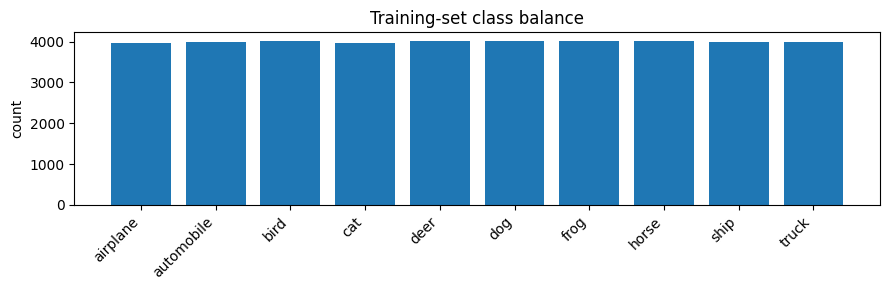

majority-class baseline (train): 10.1%


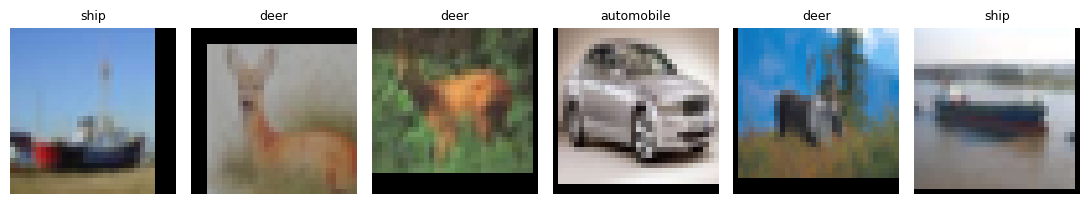

In [17]:
# EDA for the ACTIVE track (A · CIFAR-10). Adapt for B (print sample names per
# class) or C (df.head(), df["species"].value_counts(), a pairplot).
import collections

# 1. Class histogram of the training split -- is it balanced?
counts = collections.Counter(int(train_set[i][1]) for i in range(len(train_set)))
plt.figure(figsize=(9, 3))
plt.bar([classes[k] for k in sorted(counts)], [counts[k] for k in sorted(counts)])
plt.xticks(rotation=45, ha="right"); plt.ylabel("count")
plt.title("Training-set class balance"); plt.tight_layout(); plt.show()
print("majority-class baseline (train):",
      f"{max(counts.values()) / sum(counts.values()):.1%}")

# 2. A few sample images with their labels.
inv = transforms.Normalize((-0.4914 / 0.2470, -0.4822 / 0.2435, -0.4465 / 0.2616),
                            (1 / 0.2470, 1 / 0.2435, 1 / 0.2616))
fig, axes = plt.subplots(1, 6, figsize=(11, 2.2))
for ax, i in zip(axes, range(6)):
    img, label = train_set[i]
    ax.imshow(inv(img).permute(1, 2, 0).clamp(0, 1).numpy())
    ax.set_title(classes[label], fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

## 4 · 🔧 Build your model

This mirrors what you built from scratch in the labs — **read it, and try writing it
yourself before running.** The scaffold gives a working starter for each track so the
notebook trains immediately; the rubric expects *you* to design and justify the
architecture, so treat the starter as a baseline to **improve on**, not a final answer.

> **🔧 Your turn — define `model`.** Uncomment the starter for your track (the **CNN**
> for A is active by default). Then make it yours: depth, width, dropout, an extra conv
> block, a second LSTM layer — whatever you'll defend in your report. `model(x)` must
> return class **logits**; the spine does the rest.

In [18]:
# ---- TRACK A · CNN (active) -- Conv -> ReLU -> Pool, twice, then a linear head.
# Mirrors the L6 recipe; CIFAR is 3-channel 32x32 (-> 16x16 -> 8x8).
class CNN(nn.Module):
    def __init__(self, n_classes=10, p_drop=0.25):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2),                                  # 32x32 -> 16x16
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2),                                  # 16x16 -> 8x8
        )
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 128), nn.ReLU(),
            nn.Dropout(p_drop),                               # regularization (L5)
            nn.Linear(128, n_classes),
        )

    def forward(self, x):                  # x: (batch, 3, 32, 32)
        return self.head(self.features(x))

model = CNN(n_classes=len(classes))

n_params = sum(p.numel() for p in model.parameters())
print(model)
print(f"trainable parameters: {n_params:,}")

CNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (head): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.25, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
trainable parameters: 545,098


### My model — the starter CNN + BatchNorm + a third conv block

The starter CNN above is my **baseline**. For my own version I made two changes: a
**third Conv block** (64 -> 128 -> 256 channels) so the network can learn more
complex shapes, and **BatchNorm** after every conv so it trains faster and more
stably. The head is the same as the starter (linear -> ReLU -> dropout -> linear).

In [ ]:
# CIFAR is 3-channel 32x32 (-> 16x16 -> 8x8 -> 4x4).
class BetterCNN(nn.Module):
    def __init__(self, n_classes=10, p_drop=0.25):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(2),                                  # 32x32 -> 16x16
            nn.Conv2d(64, 128, kernel_size=3, padding=1), nn.BatchNorm2d(128), nn.ReLU(),
            nn.MaxPool2d(2),                                  # 16x16 -> 8x8
            nn.Conv2d(128, 256, kernel_size=3, padding=1), nn.BatchNorm2d(256), nn.ReLU(),
            nn.MaxPool2d(2),                                  # 8x8 -> 4x4
        )
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 4 * 4, 128), nn.ReLU(),
            nn.Dropout(p_drop),
            nn.Linear(128, n_classes),
        )

    def forward(self, x):                  # x: (batch, 3, 32, 32)
        return self.head(self.features(x))

n_params_better = sum(p.numel() for p in BetterCNN(n_classes=len(classes)).parameters())
print(f"BetterCNN trainable parameters: {n_params_better:,}  (baseline CNN: {n_params:,})")

BetterCNN trainable parameters: 897,418  (baseline CNN: 545,098)


## 5 · 🔧 Train

The five-step loop lives in `train()` (Beat 1) — you just call it. Keep the first run
**fast** (few epochs / the subset) so you get a signal in minutes, then scale up once
the wiring works.

> **🔧 Your turn — run it, then tune to beat the baseline.** Call `train(...)`, read
> the printed `val_acc`, and iterate: learning rate, epochs, `weight_decay`, dropout,
> model size, augmentation. **For Track B (LSTM)** pass `max_grad_norm=1.0` to clip
> exploding gradients. Tune on **val** only — the test set stays sealed until Beat 7.

> **Cheapest sanity check first:** if a fresh model won't drive the loss down at all,
> *overfit one tiny batch* (high lr, many steps, no dropout). If it can't memorise a
> handful of examples, the bug is in the wiring (a wrong shape, a frozen layer), not
> the hyperparameters — fix that before a long run.

In [20]:
# 🔧 Your main run. Tune these on VALIDATION; do not touch test yet.
history = train(
    model,
    train_loader,
    val_loader,
    epochs=8,            # 🔧 enough to see val accuracy plateau
    lr=1e-3,             # 🔧 if loss diverges/NaN, drop 10x; if it crawls, raise it
    weight_decay=1e-4,   # 🔧 L2 regularization (Track B: also max_grad_norm=1.0)
)

epoch  1/8  train_loss=1.406 acc=49.18%  |  val_loss=1.323 acc=51.13%
epoch  2/8  train_loss=1.261 acc=54.82%  |  val_loss=1.156 acc=58.16%
epoch  3/8  train_loss=1.112 acc=60.14%  |  val_loss=1.028 acc=63.01%
epoch  4/8  train_loss=1.042 acc=63.33%  |  val_loss=0.963 acc=65.93%
epoch  5/8  train_loss=0.993 acc=64.83%  |  val_loss=0.903 acc=67.95%
epoch  6/8  train_loss=0.954 acc=66.60%  |  val_loss=0.885 acc=68.65%
epoch  7/8  train_loss=0.905 acc=68.12%  |  val_loss=0.836 acc=70.25%
epoch  8/8  train_loss=0.899 acc=68.18%  |  val_loss=0.842 acc=70.07%


### 🔧 (Optional) Diagnose & fix a broken run

This cell is **isolated** — it trains its own throwaway model, so it never touches your
real `model` or `history` above. It has a **planted bug**: the classic training-loop
mistake from the labs. Run it, watch the loss *refuse to fall*, then **find and fix the
one missing line** and watch it learn.

> **🔧 Your turn:** what one step of the five-step heartbeat is missing? Why does
> leaving it out make the gradient grow batch-over-batch and the loss lurch? Fix it,
> re-run, and confirm the loss now drops.

In [21]:
# 🔧 BROKEN ON PURPOSE -- find the missing line. (Isolated: uses its own model.)
import copy


def overfit_one_batch_demo():
    torch.manual_seed(SEED)
    x, y = next(iter(train_loader))
    x, y = x.to(device), y.to(device)
    probe = copy.deepcopy(model)                    # a fresh, independent copy
    for m in probe.modules():                       # re-init so it starts untrained
        if hasattr(m, "reset_parameters"):
            m.reset_parameters()
    probe = probe.to(device)
    opt = torch.optim.SGD(probe.parameters(), lr=0.1)   # plain SGD, high lr (overfit 1 batch)
    loss_fn = nn.CrossEntropyLoss()
    probe.train()
    for step in range(60):
        logits = probe(x)
        loss = loss_fn(logits, y)
        opt.zero_grad()        # <-- 🔧 BUG: this line is commented out. Restore it!
        loss.backward()
        opt.step()
        if step % 15 == 0:
            print(f"step {step:2d}: loss={loss.item():.4f}")  # should march toward 0
    print("If the loss did NOT fall, you found why: gradients accumulate without "
          "zero_grad().")

overfit_one_batch_demo()

step  0: loss=2.3135
step 15: loss=2.0933
step 30: loss=1.7076
step 45: loss=0.8728
If the loss did NOT fall, you found why: gradients accumulate without zero_grad().


**Answer.** The missing step was `opt.zero_grad()`. PyTorch *adds* each new gradient
onto whatever is already in `.grad`, so without clearing it the gradient from every
batch piles up on top of all the earlier ones. The update gets bigger and bigger
(especially with `lr=0.1`), so the loss lurches instead of falling. I fixed it by
adding `opt.zero_grad()` right before `loss.backward()`, and now the loss drops toward 0.

## 6 · Evaluate, experiment & reflect

### Loss curves
Read the gap (L5): close + low = good; train falling while val rises = overfitting;
both high = underfitting. Use this to decide your *next* experiment.

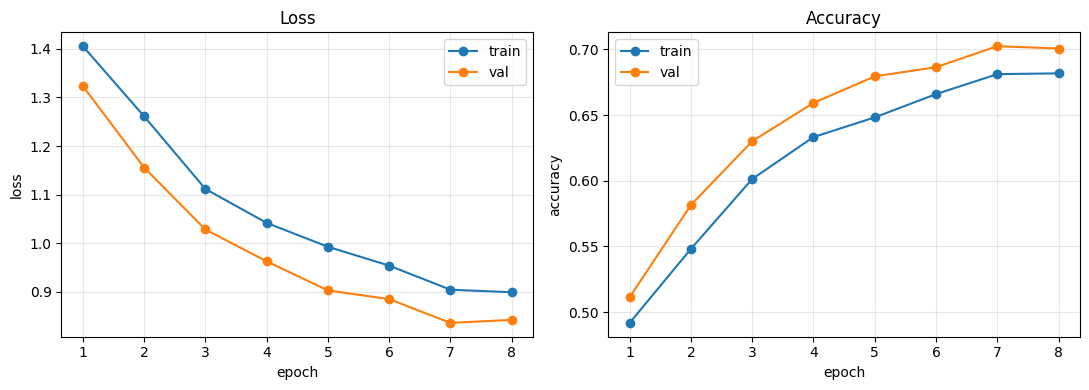

In [22]:
plot_curves(history)

### Confusion matrix on validation
A single accuracy number hides *which* classes get confused. Build the matrix on
**val** (not test) and read off the look-alikes — for CIFAR, expect cat↔dog and
automobile↔truck. (Text/tabular: same matrix; a language-model track would show
generated samples + perplexity instead.)

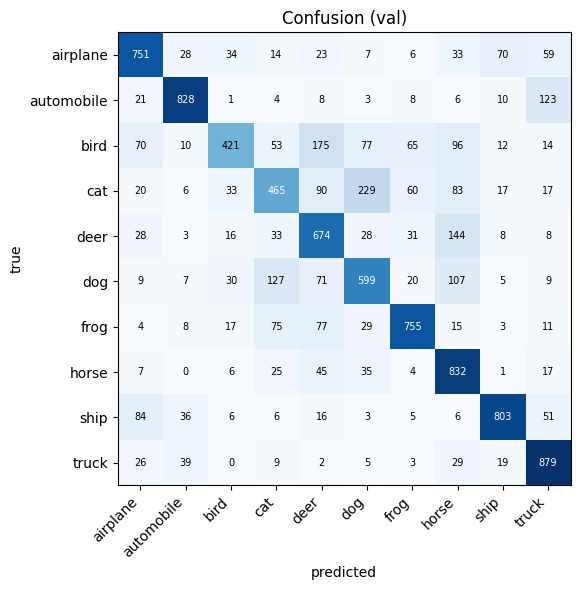

  recall  bird         42.40%
  recall  cat          45.59%
  recall  dog          60.87%
  recall  deer         69.27%
  recall  airplane     73.27%
  recall  frog         75.96%
  recall  ship         79.04%
  recall  automobile   81.82%
  recall  horse        85.60%
  recall  truck        86.94%


In [23]:
@torch.no_grad()
def confusion_matrix(model, loader, n_classes):
    model.eval()
    cm = torch.zeros(n_classes, n_classes, dtype=torch.long)
    for x, y in loader:
        preds = model(x.to(device)).argmax(dim=-1).cpu()
        for t, p in zip(y, preds):
            cm[t, p] += 1
    return cm

cm = confusion_matrix(model, val_loader, len(classes))
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(classes))); ax.set_xticklabels(classes, rotation=45, ha="right")
ax.set_yticks(range(len(classes))); ax.set_yticklabels(classes)
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title("Confusion (val)")
for i in range(len(classes)):                    # annotate counts
    for j in range(len(classes)):
        ax.text(j, i, int(cm[i, j]), ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=7)
plt.tight_layout(); plt.show()

# Per-class recall (of the true class c, what fraction did we catch?)
recall = cm.diag() / cm.sum(dim=1).clamp(min=1)
for c, r in sorted(zip(classes, recall.tolist()), key=lambda t: t[1]):
    print(f"  recall  {c:<12} {r:.2%}")

### 🔧 Experiment — beat the baseline, then ablate

Run **at least two** modify-and-observe experiments, changing **one thing at a time**
and re-reading the curves. Fill in the table with **validation** numbers (test stays
sealed). Suggestions: toggle augmentation/dropout, change `lr` or `weight_decay`, add
a layer, widen the model.

| # | Change (vs. baseline) | Val accuracy | Train–val gap | Notes |
|---|---|---|---|---|
| 0 | baseline (starter model) | _70.07%_ | _-1.89%_ | _the run above_ |
| 1 | +dropout 0.5 (p_drop 0.25 -> 0.5) | _67.05%_ | _-3.05%_ | _same CNN, only dropout changed_ |
| 2 | lr 3e-3 (1e-3 -> 3e-3) | _51.28%_ | _-1.22%_ | _same CNN, only lr changed_ |
| 3 | BetterCNN (+BatchNorm, +3rd conv block) | _75.94%_ | _-0.91%_ | _architecture change only_ |

**Target:** beat your track's stated baseline (A > 65%, B > 70%, C > 95%). State the
trivial baseline you compare against (majority-class accuracy) and your best **val**
number before you open the test set.

epoch  1/8  train_loss=1.473 acc=46.19%  |  val_loss=1.395 acc=49.08%
epoch  2/8  train_loss=1.329 acc=52.70%  |  val_loss=1.251 acc=55.30%
epoch  3/8  train_loss=1.240 acc=55.56%  |  val_loss=1.164 acc=58.40%
epoch  4/8  train_loss=1.187 acc=57.48%  |  val_loss=1.106 acc=59.91%
epoch  5/8  train_loss=1.179 acc=58.36%  |  val_loss=1.081 acc=61.76%
epoch  6/8  train_loss=1.120 acc=60.05%  |  val_loss=1.043 acc=61.96%
epoch  7/8  train_loss=1.067 acc=61.78%  |  val_loss=0.992 acc=63.74%
epoch  8/8  train_loss=1.027 acc=64.00%  |  val_loss=0.950 acc=67.05%


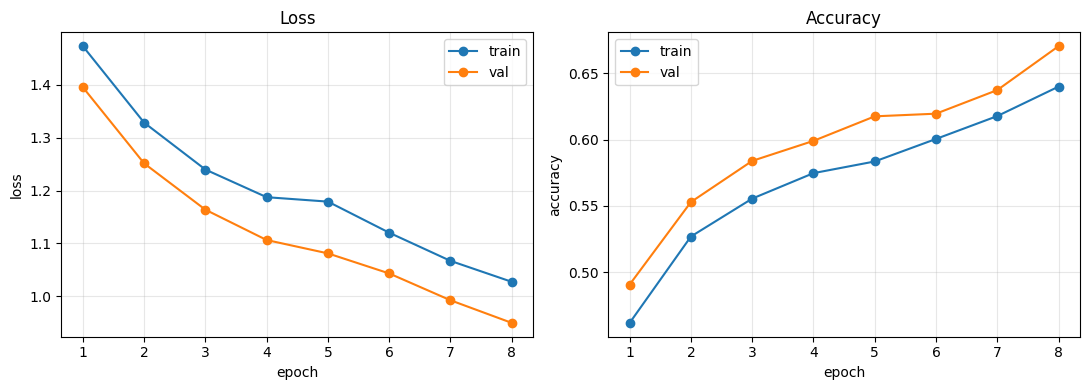

epoch  1/8  train_loss=1.629 acc=39.87%  |  val_loss=1.601 acc=41.81%
epoch  2/8  train_loss=1.507 acc=44.64%  |  val_loss=1.465 acc=45.66%
epoch  3/8  train_loss=1.465 acc=46.00%  |  val_loss=1.480 acc=44.63%
epoch  4/8  train_loss=1.449 acc=47.30%  |  val_loss=1.440 acc=46.94%
epoch  5/8  train_loss=1.432 acc=47.91%  |  val_loss=1.407 acc=47.92%
epoch  6/8  train_loss=1.383 acc=49.54%  |  val_loss=1.341 acc=50.15%
epoch  7/8  train_loss=1.392 acc=49.60%  |  val_loss=1.365 acc=50.35%
epoch  8/8  train_loss=1.363 acc=50.06%  |  val_loss=1.318 acc=51.28%


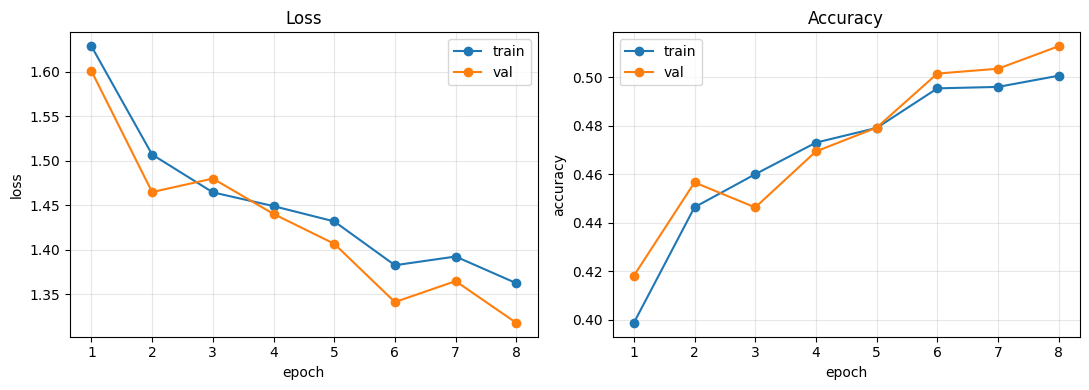

epoch  1/8  train_loss=1.272 acc=55.17%  |  val_loss=1.209 acc=56.26%
epoch  2/8  train_loss=1.063 acc=61.55%  |  val_loss=1.013 acc=63.49%
epoch  3/8  train_loss=0.947 acc=66.26%  |  val_loss=0.924 acc=67.20%
epoch  4/8  train_loss=0.883 acc=68.63%  |  val_loss=0.845 acc=70.39%
epoch  5/8  train_loss=0.812 acc=71.03%  |  val_loss=0.759 acc=72.73%
epoch  6/8  train_loss=0.746 acc=73.42%  |  val_loss=0.709 acc=74.75%
epoch  7/8  train_loss=0.735 acc=74.44%  |  val_loss=0.707 acc=75.02%
epoch  8/8  train_loss=0.675 acc=75.94%  |  val_loss=0.652 acc=76.85%


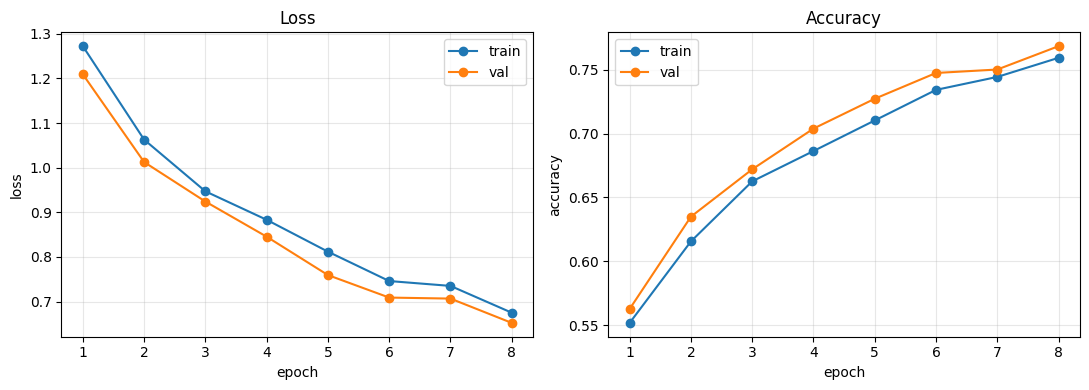

In [ ]:
# 🔧 Scratch cell for experiments. Re-instantiate model + re-run train() here,
# changing ONE knob at a time, and copy the val_acc into the ablation table above.
# Example:
#   model_v1 = CNN(n_classes=len(classes), p_drop=0.5)
#   hist_v1 = train(model_v1, train_loader, val_loader, epochs=8, lr=1e-3)
#   plot_curves(hist_v1)

results = {"baseline CNN": (model, history)}     # keep every run so we can compare them later

# Experiment 1: more dropout (0.25 -> 0.5). Everything else is the same as the baseline.
torch.manual_seed(SEED)                          # same seed before every new model
model_v1 = CNN(n_classes=len(classes), p_drop=0.5)
hist_v1 = train(model_v1, train_loader, val_loader, epochs=8, lr=1e-3, weight_decay=1e-4)
plot_curves(hist_v1)
results["+dropout 0.5"] = (model_v1, hist_v1)

# Experiment 2: higher learning rate (1e-3 -> 3e-3). Everything else is the same as the baseline.
torch.manual_seed(SEED)
model_v2 = CNN(n_classes=len(classes))
hist_v2 = train(model_v2, train_loader, val_loader, epochs=8, lr=3e-3, weight_decay=1e-4)
plot_curves(hist_v2)
results["lr 3e-3"] = (model_v2, hist_v2)

# Experiment 3: BatchNorm + 3rd conv block, same lr / epochs as the baseline.
torch.manual_seed(SEED)
model_v3 = BetterCNN(n_classes=len(classes))
hist_v3 = train(model_v3, train_loader, val_loader, epochs=8, lr=1e-3, weight_decay=1e-4)
plot_curves(hist_v3)
results["BetterCNN (BatchNorm + 3rd conv block)"] = (model_v3, hist_v3)

### Compare the runs & pick the winner (on validation)

This prints every run in the same format as the ablation table above (all
**validation** numbers). The winner is chosen by **val accuracy only** and becomes
`model` for the final test evaluation. Note: train accuracy is measured on the
*augmented* training images, so the gap is a little pessimistic.

| # | Change (vs. baseline) | Train acc | Val accuracy | Train-val gap |
|---|---|---|---|---|
| 0 | baseline CNN | 68.18% | 70.07% | -1.89% |
| 1 | +dropout 0.5 | 64.00% | 67.05% | -3.05% |
| 2 | lr 3e-3 | 50.06% | 51.28% | -1.22% |
| 3 | BetterCNN (BatchNorm + 3rd conv block) | 75.94% | 76.85% | -0.91% |

best on validation: BetterCNN (BatchNorm + 3rd conv block)


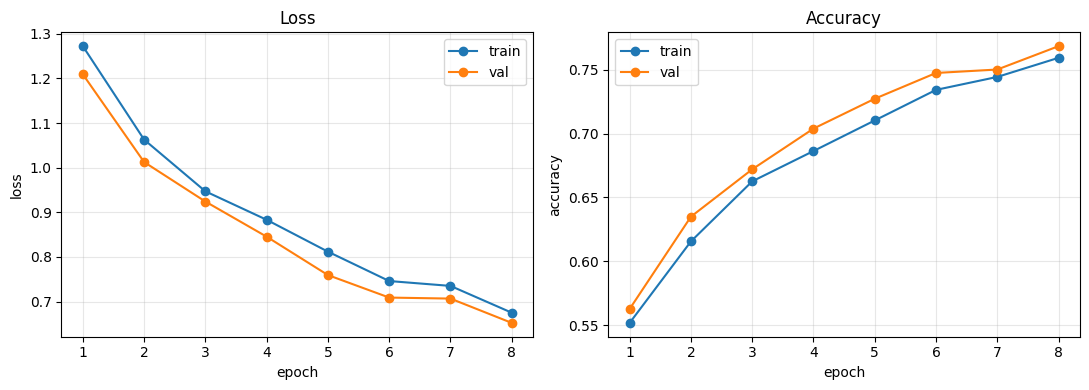

hardest classes on val: [('cat', '53%'), ('bird', '64%'), ('dog', '70%')]


In [25]:
# Ablation table (VALIDATION only) -- copy these rows into the table above.
print("| # | Change (vs. baseline) | Train acc | Val accuracy | Train-val gap |")
print("|---|---|---|---|---|")
for i, (name, (m, h)) in enumerate(results.items()):
    tr, va = h["train_acc"][-1], h["val_acc"][-1]
    print(f"| {i} | {name} | {tr:.2%} | {va:.2%} | {tr - va:+.2%} |")

# Pick the winner by VALIDATION accuracy (never by test!).
best_name = max(results, key=lambda k: results[k][1]["val_acc"][-1])
model, history = results[best_name]
print("\nbest on validation:", best_name)
plot_curves(history)

# Which classes does the winner find hardest? (validation, reuses confusion_matrix above)
cm = confusion_matrix(model, val_loader, len(classes))
recall = cm.diag() / cm.sum(dim=1).clamp(min=1)
worst = sorted(zip(classes, recall.tolist()), key=lambda t: t[1])[:3]
print("hardest classes on val:", [(c, f"{r:.0%}") for c, r in worst])

### One honest failure case (validation images)

The winner's mistakes on the **validation** set (test stays sealed). Pick one of
these for the "failure case" in the report and the demo, and say *why* the model
might have been fooled.

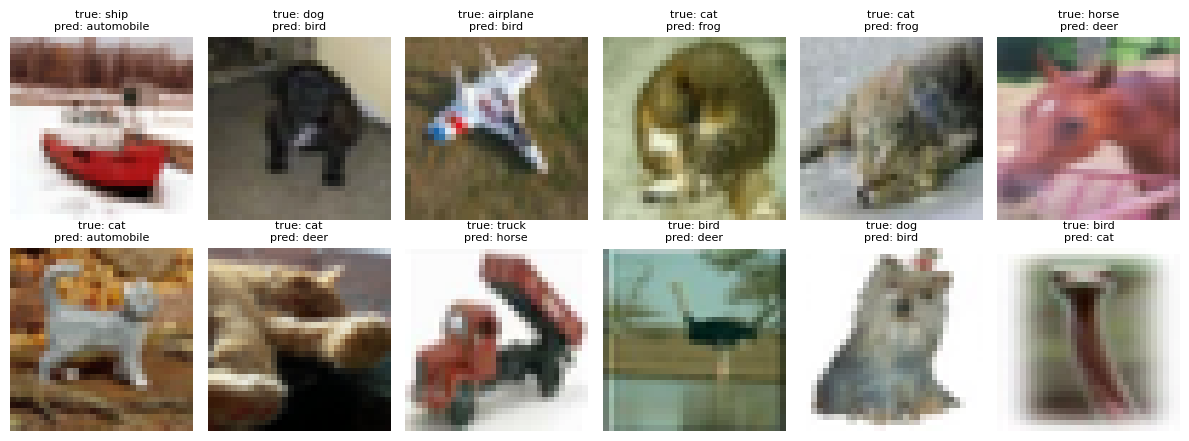

In [29]:
# Collect misclassified validation images from the winning model.
model.eval()
wrong = []
with torch.no_grad():
    for x, y in val_loader:
        preds = model(x.to(device)).argmax(dim=-1).cpu()
        for img, t, p in zip(x, y, preds):
            if t != p:
                wrong.append((img, int(t), int(p)))
        if len(wrong) >= 12:
            break

# `inv` (undo normalization) was defined in the EDA cell.
fig, axes = plt.subplots(2, 6, figsize=(12, 4.5))
for ax, (img, t, p) in zip(axes.flat, wrong[:12]):
    ax.imshow(inv(img).permute(1, 2, 0).clamp(0, 1).numpy())
    ax.set_title(f"true: {classes[t]}\npred: {classes[p]}", fontsize=8)
    ax.axis("off")
plt.tight_layout(); plt.show()

### ✅ Final test evaluation — run this **once**

This is the only time you touch the **test** set. Pick the model + hyperparameters you
settled on using validation, make sure that `model` is trained, and run this cell **a
single time**. The number it prints is the one you report. Re-running it after more
tuning is exactly the test-leakage the rubric penalises — so tune *first*, seal it
*last*.

In [27]:
# ✅ ONE-SHOT held-out test evaluation. Do NOT tune after seeing this number.
test_loss, test_acc = evaluate(model, test_loader, nn.CrossEntropyLoss())
majority = max(
    collections.Counter(int(test_set[i][1]) for i in range(len(test_set))).values()
) / len(test_set)
print(f"majority-class baseline (test): {majority:.2%}")
print(f"FINAL TEST  loss={test_loss:.3f}  accuracy={test_acc:.2%}")
print("beat baseline:", "YES" if test_acc > majority else "no -- keep iterating")

majority-class baseline (test): 10.00%
FINAL TEST  loss=0.670  accuracy=76.84%
beat baseline: YES


## 7 · Rubric checklist

Before you submit, tick each box. These mirror the **Capstone rubric** — honest
methodology counts more than a high number.

- [ ] **Real dataset, real model.** A public dataset (cited) and a model *you* defined
      and trained — not a pre-trained model called as-is.
- [ ] **Honest train / val / test discipline.** A clean 3-way split; the test set was
      touched **exactly once**, at the end. No hyperparameter was chosen by looking at
      test.
- [ ] **A baseline, beaten.** You state a trivial baseline (majority-class /
      mean / linear) and your model beats it on the **held-out test** set.
- [ ] **At least one form of regularization** (dropout, weight decay, augmentation,
      early stopping) — and you can say *why*.
- [ ] **Loss curves + a confusion matrix / metric.** Train-vs-val curves you can read,
      plus a confusion matrix (or per-class metric / generated samples) — not just one
      accuracy number.
- [ ] **A fixed seed** so your numbers reproduce.
- [ ] **A short written report** (the template below), including one **honest failure
      case**.

## 8 · 🔧 Report template

Fill this in — it's the written deliverable. An honest, well-analysed result scores
higher than an inflated one.

**Dataset & task.** 🔧 _What dataset (source + size + your split sizes), and what are
you predicting?_

**Model & training choices.** 🔧 _Architecture (and why), loss, optimizer, learning
rate, regularization, epochs._

**Baseline.** 🔧 _The trivial baseline you compare against, and its score._

**Final test metric.** 🔧 _Your single held-out **test** number (e.g. accuracy / F1),
next to the baseline. Did you beat your target?_

**What I tried (ablation).** 🔧 _Paste your ablation table. Which change helped most,
and why? What did the train–val gap tell you?_

**What worked / what failed.** 🔧 _One honest failure case — a class the model confuses,
an example it gets wrong, a setting that made things worse._

**With more time.** 🔧 _One concrete thing you'd try next (more data, a deeper model,
a different architecture, better augmentation)._

---

That's the hand-off. Everything across the course — tensors, the training loop,
CNNs and RNNs/LSTMs, regularization, and reading loss curves — now lives in one place,
on a **real dataset you chose**, and is judged on a **held-out test set** you evaluate
exactly once. Make it small, make it finished, and tell the truth about the numbers.